In [ ]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/CAR DETAILS FROM CAR DEKHO - CAR DETAILS FROM CAR DEKHO.csv")


In [ ]:
#Data understanding
print(df.head())

                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 4340
Columns: 8


In [ ]:
print(df.isnull().sum())

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [ ]:
df.duplicated().sum()

np.int64(763)

In [ ]:
#Data cleaning
df = df.drop_duplicates()

print(len(df))

3577


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3577 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           3577 non-null   object
 1   year           3577 non-null   int64 
 2   selling_price  3577 non-null   int64 
 3   km_driven      3577 non-null   int64 
 4   fuel           3577 non-null   object
 5   seller_type    3577 non-null   object
 6   transmission   3577 non-null   object
 7   owner          3577 non-null   object
dtypes: int64(3), object(5)
memory usage: 251.5+ KB


In [ ]:
print(df["fuel"].value_counts())
print(df["seller_type"].value_counts())
print(df["transmission"].value_counts())
print(df["owner"].value_counts())

fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64
seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64
owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64


In [ ]:
print("Final dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Final dataset shape: (3577, 8)
Missing values: 0
Duplicate rows: 0


In [ ]:
#EDA and statistics
df.describe()

,year,selling_price,km_driven
count,3577.000000,3.577000e+03,3577.000000
mean,2012.962538,4.739125e+05,69250.545709
std,4.251759,5.093018e+05,47579.940016
min,1992.000000,2.000000e+04,1.000000
25%,2010.000000,2.000000e+05,36000.000000
50%,2013.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [ ]:
df.describe(include="object")

,name,fuel,seller_type,transmission,owner
count,3577,3577,3577,3577,3577
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,54,1800,2832,3265,2218


In [ ]:
print("Mean selling price:", df["selling_price"].mean())
print("Median selling price:", df["selling_price"].median())
print("Standard deviation:", df["selling_price"].std())

Mean selling price: 473912.54207436397
Median selling price: 350000.0
Standard deviation: 509301.8098160385


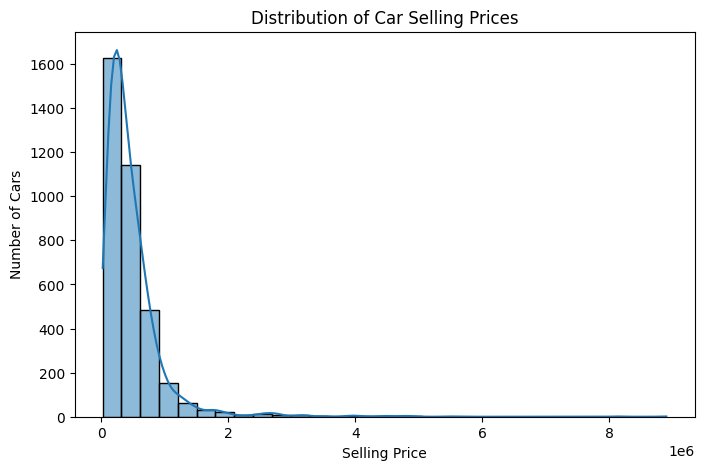

In [ ]:
#Visualization
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="selling_price", bins=30, kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

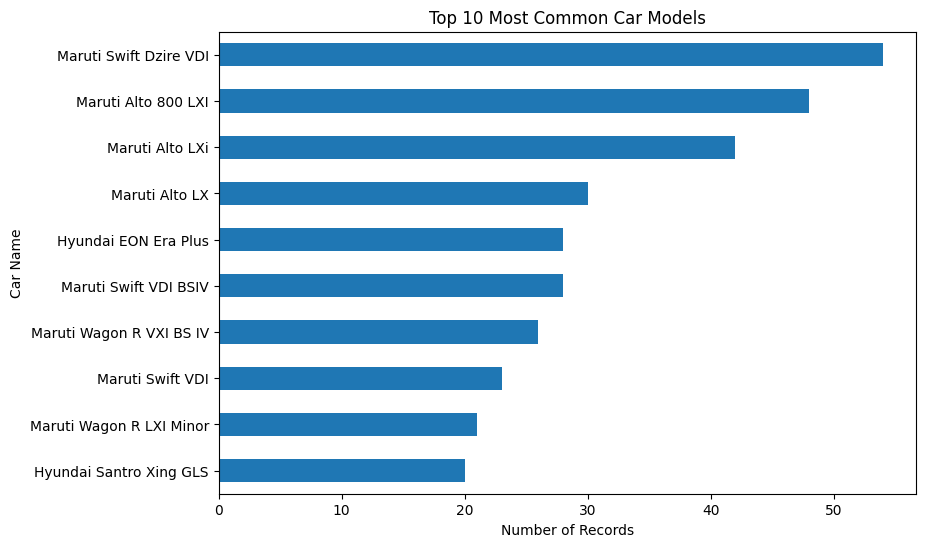

In [ ]:
plt.figure(figsize=(9, 6))
df["name"].value_counts().head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Most Common Car Models")
plt.xlabel("Number of Records")
plt.ylabel("Car Name")
plt.show()

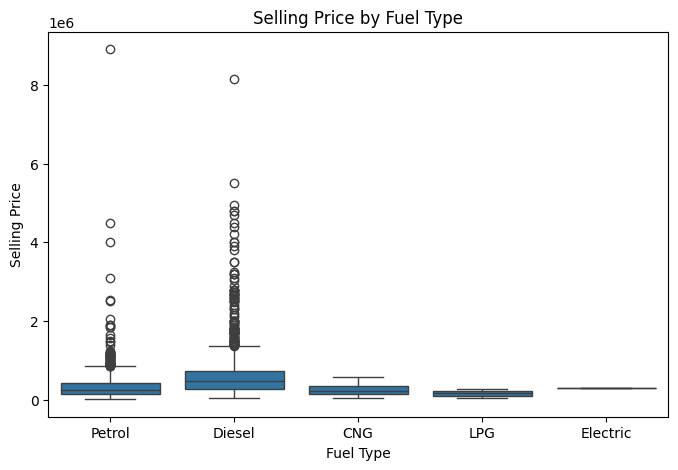

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="fuel", y="selling_price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.show()

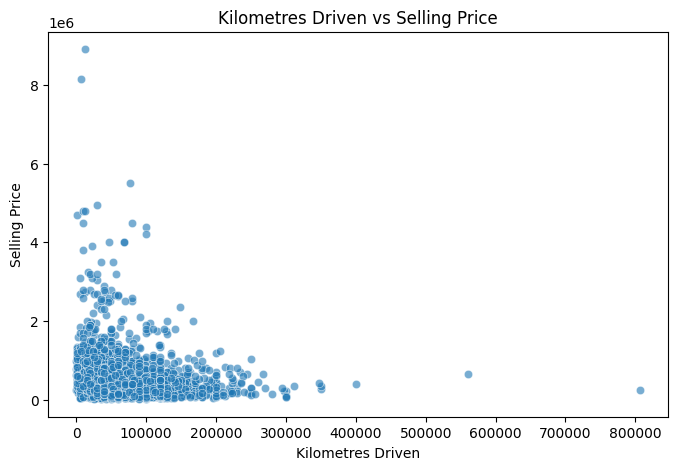

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.6)
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.show()

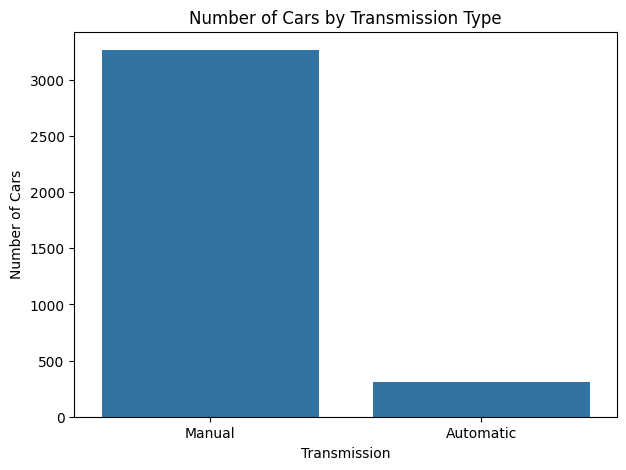

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="transmission")
plt.title("Number of Cars by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")
plt.show()

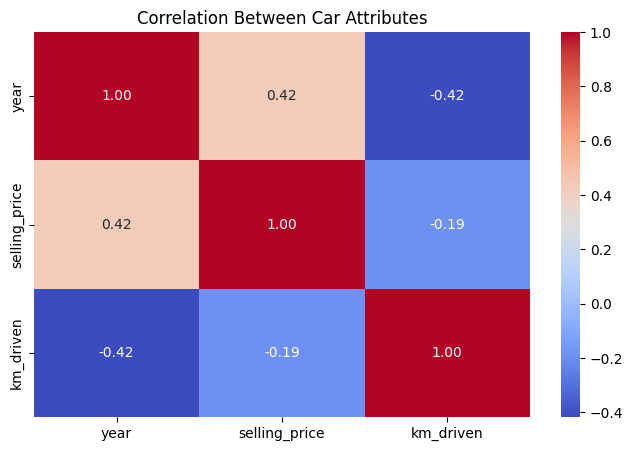

In [ ]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    df[["year", "selling_price", "km_driven"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Car Attributes")
plt.show()

In [ ]:
#Insights and conclusions
print("1. Most common car name:")
print(df["name"].value_counts().head(1))

print("\n2. Average selling price:")
print(df["selling_price"].mean())

print("\n3. Median selling price:")
print(df["selling_price"].median())

print("\n4. Most common fuel type:")
print(df["fuel"].value_counts().idxmax())

print("\n5. Correlation between kilometres driven and selling price:")
print(df["km_driven"].corr(df["selling_price"]))

1. Most common car name:
name
Maruti Swift Dzire VDI    54
Name: count, dtype: int64

2. Average selling price:
473912.54207436397

3. Median selling price:
350000.0

4. Most common fuel type:
Diesel

5. Correlation between kilometres driven and selling price:
-0.1873589193668392
